# 02 – Training the model

In this notebook you train a neural network to recognise land types from satellite images. You don't need to write anything. Read each explanation, run the cell (**Shift + Enter**), and look at what comes out.

**The plan:**
1. Prepare the images the way the model wants them (resize, flip, normalise)
2. Split them into train / validation / test
3. Load **ResNet50**, a network already trained on 14 million everyday photos
4. Look inside it: what does it "see"?
5. Train it in two stages, and watch it learn in real time
6. See its predictions on images it has never seen

**Time:** the two training cells take about 10 minutes in total on your RTX 5060 (about 1 minute per epoch). Everything else is quick.

**If anything breaks:** menu **Kernel → Restart Kernel and Run All Cells**.

## Step 1 – Setup

Loading the libraries. The new ones compared to notebook 01:

| Library | What it is |
|---|---|
| `torch` | **PyTorch**, the machine learning library. Does the maths, runs things on the GPU. |
| `torch.nn` | Building blocks for neural networks (layers, loss functions) |
| `torchvision` | Extra PyTorch tools for images: datasets, transforms, pretrained models |

`device` decides where the maths happens. `"cuda"` means your NVIDIA GPU, which can do thousands of multiplications at once. That's why training is fast.

In [1]:
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from tqdm.auto import tqdm

DATA_DIR = Path("C:/data/EuroSAT")
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.benchmark = True   # let the GPU try a few ways of doing each layer and keep the fastest
print("Running on:", device, "-", torch.cuda.get_device_name(0) if device == "cuda" else "no GPU found!")

Running on: cuda - NVIDIA GeForce RTX 5060 Laptop GPU


## Step 2 – Preparing images: resize, flip, normalise

Before an image goes into the model it passes through a **transform**: a chain of steps, applied in order.

**Resize to 224 × 224.** ResNet50 was built for 224 × 224 photos. Our images are 64 × 64, so we stretch them up. This adds no new detail (it's like zooming in on a small photo) but it gives the network the input size it's designed for.

**Random flips (training only).** Each time a training image is loaded, there's a 50% chance it's flipped left-right and a 50% chance it's flipped upside-down. From space there's no "right way up", so a flipped forest is still a forest. The model sees slightly different versions each time, which helps it learn the *pattern* instead of memorising exact images. This trick is called **data augmentation**.

**ToTensor.** Converts the image into a PyTorch **tensor** (PyTorch's name for a grid of numbers, like numpy arrays) and scales the 0–255 values down to 0–1. It also reorders the shape from (height, width, colour) to **(colour, height, width)**, which is the order PyTorch expects.

**Normalise.** Shifts the numbers so they're centred around 0. For each colour channel: `(value − mean) ÷ std`. We use the averages from ImageNet (the 14 million photos ResNet50 learned from), so our images look "statistically familiar" to it.

We make **two** transforms: one with flips for training, one without for validation/testing. When we're *measuring* the model, we want the real, unmodified images.

In [18]:
MEAN = [0.485, 0.456, 0.406]   # ImageNet average for red, green, blue
STD  = [0.229, 0.224, 0.225]   # ImageNet spread for red, green, blue

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

**See it.** Here's one image: the original, the resized version, and 4 random augmented versions. Run the cell a few times. The flips change each time because they're random.

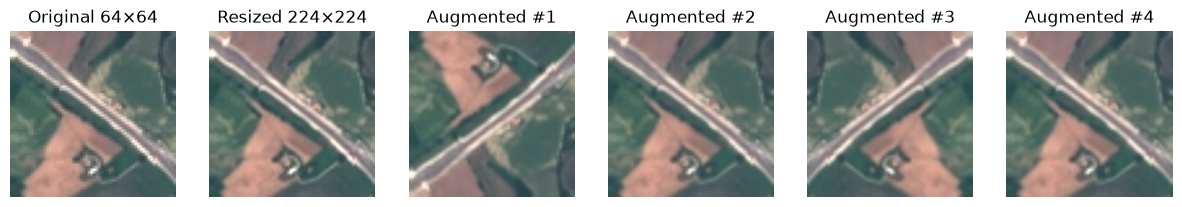

In [19]:
example = Image.open(DATA_DIR / "Highway" / "Highway_1.jpg")
resize_and_flip = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
])

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(example)
axes[0].set_title("Original 64×64")
axes[1].imshow(example.resize((224, 224)))
axes[1].set_title("Resized 224×224")
for i in range(2, 6):
    axes[i].imshow(resize_and_flip(example))
    axes[i].set_title(f"Augmented #{i - 1}")
for ax in axes:
    ax.axis("off")
plt.show()

**And the numbers.** What normalisation does to the pixel values of that same image:

Before: shape (64, 64, 3)  values from 37 to 255
After:  shape (3, 224, 224)  values from -1.48 to 2.43


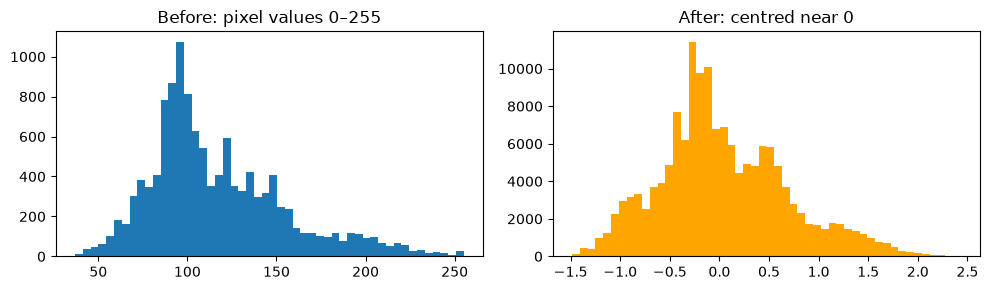

In [4]:
before = np.array(example)
after = eval_transform(example)

print("Before: shape", before.shape, " values from", before.min(), "to", before.max())
print("After:  shape", tuple(after.shape), " values from", round(after.min().item(), 2), "to", round(after.max().item(), 2))

plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1); plt.hist(before.flatten(), bins=50); plt.title("Before: pixel values 0–255")
plt.subplot(1, 2, 2); plt.hist(after.flatten().numpy(), bins=50, color="orange"); plt.title("After: centred near 0")
plt.tight_layout(); plt.show()

Notice two things: the shape changed from `(64, 64, 3)` to `(3, 224, 224)` (resized, and colour moved to the front), and the values moved from 0–255 to roughly −2…+1. Same picture, different number format.

## Step 3 – Split into train / validation / test

`ImageFolder` reads our folder structure and labels each image by its folder name. It numbers the classes alphabetically: AnnualCrop = 0, Forest = 1, … SeaLake = 9 (the same order you saw in notebook 01).

Then we split the 27,000 images three ways:

| Set | Share | Purpose | Analogy |
|---|---|---|---|
| **Train** | 80% | The model learns from these | Textbook exercises |
| **Validation** | 10% | Checked after every round to see if it's *really* learning | Practice tests |
| **Test** | 10% | Used **once**, at the very end, for the final score (notebook 03) | The real exam |

If you tested on images the model trained on, it could just memorise answers and look perfect. That's called **overfitting**.

**Fixing a bug in the guide.** The guide splits a single dataset, which means all three sets share the training transform, so validation and test images would get randomly flipped too. Instead we load the folder **twice** (once with each transform), shuffle the image numbers once, and hand out the pieces. The training set gets flips; validation and test don't.

`manual_seed(42)` makes the "random" shuffle the same every time you run it. So notebook 03 can rebuild the exact same test set. (42 is arbitrary; any fixed number works.)

In [5]:
train_data = datasets.ImageFolder(DATA_DIR, transform=train_transform)
eval_data  = datasets.ImageFolder(DATA_DIR, transform=eval_transform)
class_names = train_data.classes

shuffled = torch.randperm(len(train_data), generator=torch.Generator().manual_seed(42)).tolist()
n_train = int(0.8 * len(shuffled))
n_val   = int(0.1 * len(shuffled))

train_set = Subset(train_data, shuffled[:n_train])
val_set   = Subset(eval_data,  shuffled[n_train:n_train + n_val])
test_set  = Subset(eval_data,  shuffled[n_train + n_val:])

print("Classes:", class_names)
print(f"Train: {len(train_set)}   Validation: {len(val_set)}   Test: {len(test_set)}")

Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Train: 21600   Validation: 2700   Test: 2700


## Step 4 – Batches

The model doesn't look at one image at a time, or all 21,600 at once. It looks at a **batch** of 64. Why 64?
- One at a time is slow and the learning signal is noisy
- All at once won't fit in your GPU's 8 GB of memory
- 32–64 is the usual middle ground; 64 keeps your GPU busier

A `DataLoader` serves up batches. `shuffle=True` for training mixes the order every round, so the model can't learn anything from the order images arrive in.

**Speed settings:**
- `num_workers=8`: 8 CPU helper processes open, resize and flip images *in parallel* while the GPU is busy with the previous batch. With 0 workers, the GPU sits idle waiting for the CPU (that's why your GPU was only ~50% busy in the first test).
- `pin_memory=True`: puts batches in a special part of RAM the GPU can copy from faster.
- `persistent_workers=True`: keeps the helpers alive between epochs instead of restarting them.

The first time you ask for a batch it takes a few seconds while the 8 workers start up.

Remember the last question from notebook 01? Here's the answer: the batch shape.

In [6]:
BATCH_SIZE = 64
NUM_WORKERS = 8
loader_settings = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)

train_loader = DataLoader(train_set, shuffle=True, **loader_settings)
val_loader   = DataLoader(val_set,   shuffle=False, **loader_settings)

images, labels = next(iter(train_loader))
print("Batch of images:", tuple(images.shape), "  ->  (images, colours, height, width)")
print("Batch of labels:", tuple(labels.shape))
print("First 8 labels as numbers:", labels[:8].tolist())
print("First 8 labels as names:  ", [class_names[i] for i in labels[:8]])

Batch of images: (64, 3, 224, 224)   ->  (images, colours, height, width)
Batch of labels: (64,)
First 8 labels as numbers: [7, 5, 6, 8, 7, 7, 7, 2]
First 8 labels as names:   ['Residential', 'Pasture', 'PermanentCrop', 'River', 'Residential', 'Residential', 'Residential', 'HerbaceousVegetation']


So a batch is a block of **64 × 3 × 224 × 224 = 9.6 million numbers**, plus 64 answer labels.

Let's look at the batch as pictures. To display them we have to **undo** the normalisation (`value × std + mean`), otherwise the colours look strange. Some may appear flipped. That's the augmentation.

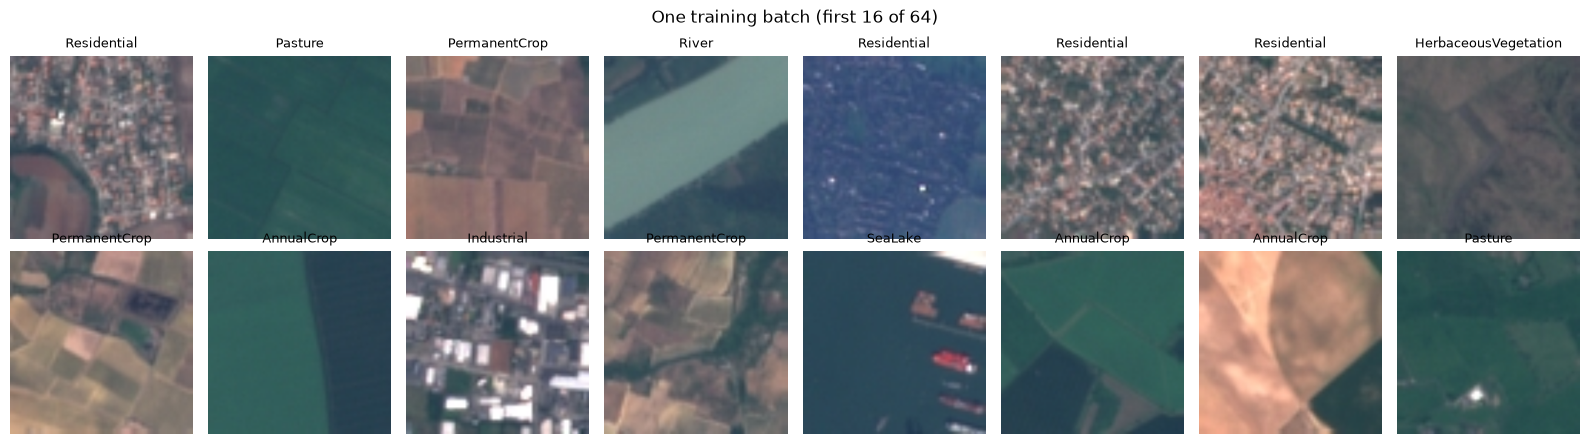

In [7]:
def to_picture(tensor):
    # undo Normalize, then put colour last again so matplotlib can draw it
    t = tensor.cpu() * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
    return t.clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(to_picture(images[i]))
    ax.set_title(class_names[labels[i]], fontsize=9)
    ax.axis("off")
plt.suptitle("One training batch (first 16 of 64)")
plt.tight_layout(); plt.show()

## Step 5 – Load ResNet50

**ResNet50** is a convolutional neural network with 50 layers, built by Microsoft researchers in 2015. It has already been trained on **ImageNet**: 14 million photos of dogs, cars, food, buildings…

Through that training it learned to see general things: edges, colours, textures, shapes. Those are useful for satellite images too. A texture is a texture.

**Transfer learning** = reuse that knowledge instead of starting from zero:
1. **Freeze** all of its layers so they don't change (`requires_grad = False` means "don't adjust these")
2. **Replace the last layer.** Originally it picks between 1,000 ImageNet categories; we swap in a fresh layer that picks between our **10** land types
3. Train only that new last layer

The first time, this downloads the pretrained weights (~100 MB).

**Parameters** are the adjustable numbers inside the network (also called **weights**). Learning = adjusting them. Watch how many there are, and how few we train at first.

In [8]:
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
print(f"Total parameters in ResNet50: {sum(p.numel() for p in model.parameters()):,}")

for param in model.parameters():
    param.requires_grad = False

print("Original last layer:", model.fc)
model.fc = nn.Linear(model.fc.in_features, len(class_names))
print("New last layer:     ", model.fc)

model = model.to(device, memory_format=torch.channels_last)   # a memory layout that's faster on modern GPUs
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parameters we will train now: {trainable:,}")

Total parameters in ResNet50: 25,557,032
Original last layer: Linear(in_features=2048, out_features=1000, bias=True)
New last layer:      Linear(in_features=2048, out_features=10, bias=True)
Parameters we will train now: 20,490


`Linear(in_features=2048, out_features=10)` means: the network boils each image down to **2,048 numbers** describing it (its "features"), and the last layer turns those into **10 scores**, one per land type. The highest score is the prediction.

We're training only ~20,000 of ~25.6 million parameters. That's why it's fast.

## Step 6 – Look inside the network

### The first layer's filters

The very first layer has **64 filters**, each a tiny 7 × 7 colour pattern. The layer slides each filter across the image and asks *"how much does this spot look like my pattern?"*

These are the filters ResNet50 learned from ImageNet. Look for edge detectors (light/dark stripes at different angles) and colour blobs. Nobody programmed these; the network discovered them by itself.

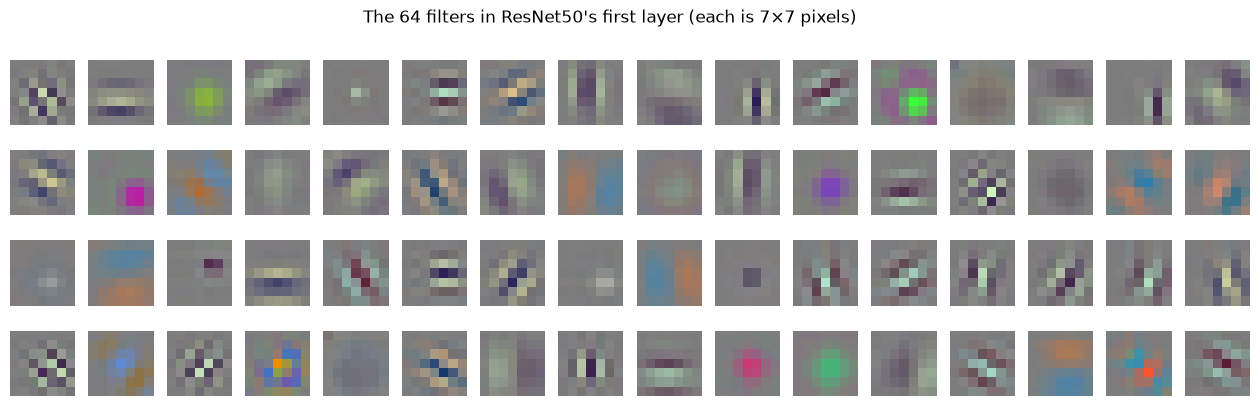

In [9]:
filters = model.conv1.weight.detach().cpu()           # shape: (64 filters, 3 colours, 7, 7)
filters = (filters - filters.min()) / (filters.max() - filters.min())   # stretch to 0–1 so we can draw them

fig, axes = plt.subplots(4, 16, figsize=(16, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(filters[i].permute(1, 2, 0))
    ax.axis("off")
plt.suptitle("The 64 filters in ResNet50's first layer (each is 7×7 pixels)")
plt.show()

### What the layers "see" in one image

When an image goes through a layer, each filter produces a **feature map**: a black-and-white picture where bright = "my pattern is here".

Below: one image from the validation set, then
- **Row 1:** 8 feature maps from the **1st layer**. Simple stuff: edges, bright/dark areas. Still looks like the image.
- **Row 2:** 8 feature maps from **deeper inside** (after ~10 layers). More abstract: combinations of patterns. Smaller and blurrier, because each pixel now summarises a bigger area.

By the end of the network (50 layers), it's no longer a picture at all, just those 2,048 descriptive numbers.

Image: Forest
Layer-1 output: (1, 64, 112, 112)   ->  64 feature maps of 112×112
Deeper output:  (1, 512, 28, 28)   ->  512 feature maps of 28×28


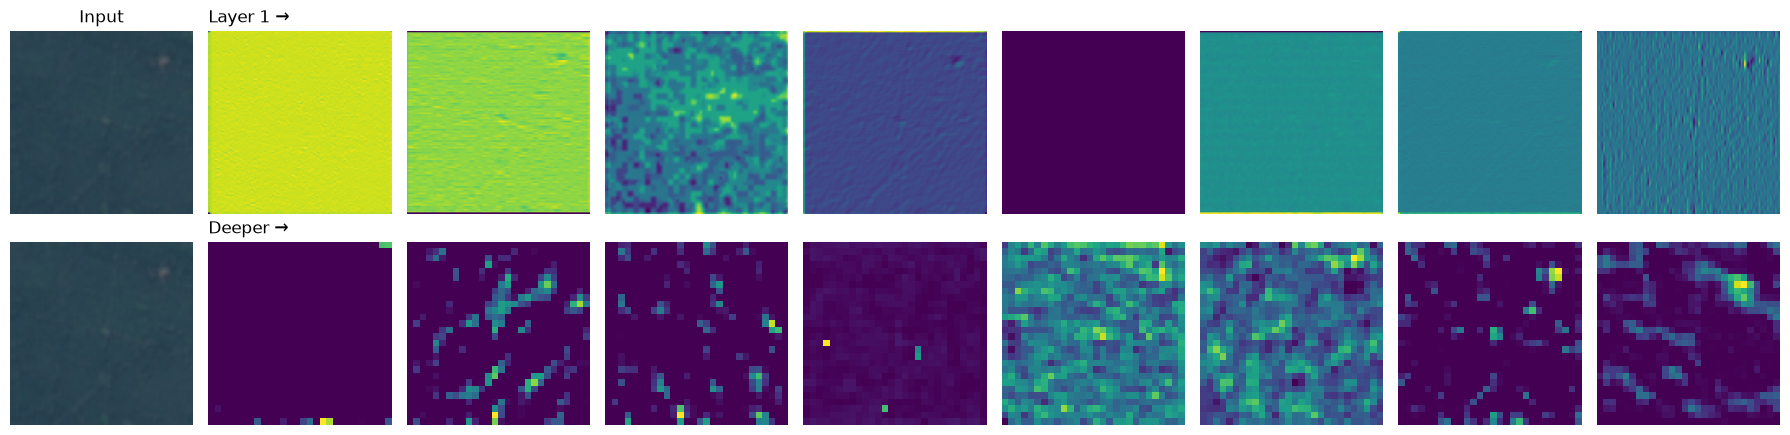

In [10]:
sample_image, sample_label = val_set[0]

model.eval()
with torch.no_grad():
    x = sample_image.unsqueeze(0).to(device)               # add a batch dimension: (1, 3, 224, 224)
    early = model.relu(model.bn1(model.conv1(x)))           # after layer 1
    deeper = model.layer2(model.layer1(model.maxpool(early)))   # ~10 layers further in

print("Image:", class_names[sample_label])
print("Layer-1 output:", tuple(early.shape), "  ->  64 feature maps of 112×112")
print("Deeper output: ", tuple(deeper.shape), "  ->  512 feature maps of 28×28")

fig, axes = plt.subplots(2, 9, figsize=(18, 4.5))
for row in axes:
    row[0].imshow(to_picture(sample_image))
for i in range(8):
    axes[0, i + 1].imshow(early[0, i].cpu(), cmap="viridis")
    axes[1, i + 1].imshow(deeper[0, i].cpu(), cmap="viridis")
axes[0, 0].set_title("Input")
axes[0, 1].set_title("Layer 1 →", loc="left")
axes[1, 1].set_title("Deeper →", loc="left")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.show()

## Step 7 – Before training: how good is it?

The new last layer starts with **random** numbers, so the model is just guessing. With 10 classes, random guessing gets about **10%** right. Let's check on the batch from Step 4.

`model(images)` gives 10 scores per image; `.argmax(1)` picks the position of the highest score, which is the predicted class number.

In [11]:
with torch.no_grad():
    outputs = model(images.to(device))
predictions = outputs.argmax(1).cpu()

print("Scores for the first image (one per class):")
print(outputs[0].cpu().numpy().round(2))
print()
print("Predicted:", [class_names[i] for i in predictions[:6]])
print("Actual:   ", [class_names[i] for i in labels[:6]])
print(f"Correct: {(predictions == labels).sum().item()} out of {len(labels)}")

Scores for the first image (one per class):
[ 0.    0.33 -0.33  0.06  0.23  0.12 -0.25 -0.24  0.1  -0.02]

Predicted: ['Forest', 'AnnualCrop', 'Highway', 'AnnualCrop', 'Forest', 'Forest']
Actual:    ['Residential', 'Pasture', 'PermanentCrop', 'River', 'Residential', 'Residential']
Correct: 8 out of 64


## Step 8 – How learning works

Training repeats the same 5 steps for every batch:

| Step | Code | In plain English |
|---|---|---|
| 1 | `optimizer.zero_grad()` | Forget the corrections from the last batch |
| 2 | `outputs = model(images)` | The model makes its guesses (**forward pass**) |
| 3 | `loss = criterion(outputs, labels)` | Measure **how wrong** the guesses were: one number, the **loss** |
| 4 | `loss.backward()` | Work out, for every trainable parameter, which direction to nudge it to reduce the loss (**backpropagation**) |
| 5 | `optimizer.step()` | Nudge all those parameters a little bit in that direction |

**Loss** (`CrossEntropyLoss`): low when the model gives a high score to the right answer, high when it's confidently wrong. Training = making this number go down.

**Optimizer** (`Adam`): does the nudging. The **learning rate** (`lr`) is how big each nudge is. Too big and it overshoots; too small and it takes forever.

**Epoch** = one full pass through all 21,600 training images (= 338 batches of 64). After each epoch we test on the validation set, to see whether it's genuinely improving.

**Mixed precision (speed trick).** Normally every number is stored with 32 bits of precision. Inside `torch.autocast(..., dtype=torch.bfloat16)` the GPU does most of the maths with 16-bit numbers instead: half the memory, and your RTX 5060's **tensor cores** (special hardware for exactly this) can do it several times faster. Neural networks barely notice the lost precision. This is the single biggest speed-up in this notebook.

**Triton / `torch.compile` (optional speed trick).** `torch.compile` reads the whole network and uses **Triton** to write custom GPU code that fuses many small steps into fewer big ones. Measured on your RTX 5060:

| | Time per batch | One-off cost |
|---|---|---|
| Normal | 136 ms | none |
| Compiled with Triton | 114 ms (1.2× faster) | ~100 s to compile at the start of *each* stage |

Why compile again for stage 2? The compiled code bakes in which layers are frozen. When we tested it without recompiling, stage 2 silently skipped the fine-tuning (no error, just worse accuracy). A good lesson: speed tricks can quietly change results, so always compare against a normal run.

For our short 10-epoch run, the compile time costs more than it saves, so `USE_COMPILE` is `False`. Set it to `True` to see it yourself; it pays off for long runs (dozens of epochs).

**Progress bar.** `tqdm` wraps the loop and draws a live bar showing how many batches are done, the speed, time remaining, and the current loss and accuracy.

The cell below defines this as reusable functions. Nothing runs yet. It's a recipe that the training cells after it use.

- `model.train()` / `model.eval()` switch the network between learning mode and testing mode (a few layers behave slightly differently)
- `torch.no_grad()` means "don't track corrections", since we're only measuring and not learning, which is faster
- Every time validation accuracy beats its best so far, we **save** the model to a file, so you keep the best version even if it gets worse later

In [12]:
criterion = nn.CrossEntropyLoss()
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
MODEL_PATH = MODEL_DIR / "resnet50_eurosat.pth"

USE_COMPILE = False


def to_gpu(images, labels):
    images = images.to(device, non_blocking=True, memory_format=torch.channels_last)
    return images, labels.to(device, non_blocking=True)


def train_one_epoch(optimizer, description):
    model.train()
    total_loss, correct, seen = 0.0, 0, 0
    bar = tqdm(train_loader, desc=description, leave=False)
    for images, labels in bar:
        images, labels = to_gpu(images, labels)
        optimizer.zero_grad()                       # 1. forget old corrections
        with torch.autocast("cuda", dtype=torch.bfloat16):
            outputs = fast_model(images)            # 2. guess
            loss = criterion(outputs, labels)       # 3. how wrong?
        loss.backward()                             # 4. work out corrections
        optimizer.step()                            # 5. apply them
        total_loss += loss.item() * len(labels)
        correct += (outputs.argmax(1) == labels).sum().item()
        seen += len(labels)
        bar.set_postfix(loss=f"{total_loss / seen:.3f}", acc=f"{correct / seen:.1%}")
    return total_loss / seen, correct / seen


def evaluate(loader):
    model.eval()
    total_loss, correct, seen = 0.0, 0, 0
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
        for images, labels in tqdm(loader, desc="  checking validation", leave=False):
            images, labels = to_gpu(images, labels)
            outputs = fast_model(images)
            total_loss += criterion(outputs, labels).item() * len(labels)
            correct += (outputs.argmax(1) == labels).sum().item()
            seen += len(labels)
    return total_loss / seen, correct / seen


def train(optimizer, epochs, stage):
    global fast_model
    if USE_COMPILE:
        torch._dynamo.reset()   # throw away code compiled for the last stage: it assumed which layers were frozen
    fast_model = torch.compile(model) if USE_COMPILE else model   # same weights either way; only the speed differs
    best = max(history["val_acc"], default=0)
    for epoch in range(1, epochs + 1):
        start = time.time()
        train_loss, train_acc = train_one_epoch(optimizer, f"{stage} epoch {epoch}/{epochs}")
        val_loss, val_acc = evaluate(val_loader)
        for key, value in zip(history, (train_loss, train_acc, val_loss, val_acc)):
            history[key].append(value)
        line = (f"{stage} epoch {epoch}/{epochs} | train loss {train_loss:.3f}, acc {train_acc:.1%}"
                f" | val loss {val_loss:.3f}, acc {val_acc:.1%} | {time.time() - start:.0f}s")
        if val_acc > best:
            best = val_acc
            torch.save(model.state_dict(), MODEL_PATH)
            line += "  <- best so far, saved"
        print(line)

## Step 9 – Training, stage 1: only the last layer

The 25.6 million pretrained parameters stay frozen; only the new last layer learns. Learning rate 0.001.

**What to watch for in each printed line:**
- **loss** going **down** → the model is getting less wrong
- **acc** (accuracy) going **up**
- **train** vs **val**: if train accuracy keeps rising but val stops improving, the model is starting to memorise (overfit)

Expect validation accuracy to jump to ~85–90% after the very first epoch. Each epoch takes about a minute. While it runs, the cell shows `[*]` on its left.

In [13]:
EPOCHS_FROZEN = 5

optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)
train(optimizer, EPOCHS_FROZEN, "Stage 1")

Stage 1 epoch 1/5:   0%|          | 0/338 [00:00<?, ?it/s]

  checking validation:   0%|          | 0/43 [00:24<?, ?it/s]

Stage 1 epoch 1/5 | train loss 0.674, acc 82.8% | val loss 0.379, acc 88.8% | 75s  <- best so far, saved


Stage 1 epoch 2/5:   0%|          | 0/338 [00:00<?, ?it/s]

  checking validation:   0%|          | 0/43 [00:00<?, ?it/s]

...

  checking validation:   0%|          | 0/43 [00:00<?, ?it/s]

Stage 1 epoch 4/5 | train loss 0.242, acc 92.6% | val loss 0.220, acc 93.4% | 23s  <- best so far, saved


Stage 1 epoch 5/5:   0%|          | 0/338 [00:00<?, ?it/s]

  checking validation:   0%|          | 0/43 [00:00<?, ?it/s]

Stage 1 epoch 5/5 | train loss 0.220, acc 93.1% | val loss 0.214, acc 93.0% | 24s


## Step 10 – Training, stage 2: fine-tune everything

Now we **unfreeze** all layers and train the whole network, but with a learning rate 10× smaller (0.0001). The pretrained layers learned from everyday photos; this lets them adjust *slightly* to satellite images. A small learning rate means gentle nudges, so we don't wreck what they already know.

Each batch now does much more work (updating 25.6 million parameters instead of 20,000), yet in our tests the epoch time stayed about the same, because reading and resizing images is the slower part. It usually pushes accuracy from ~90% to ~97–98%.

In [14]:
EPOCHS_FINETUNE = 5

for param in model.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
train(optimizer, EPOCHS_FINETUNE, "Stage 2")

Stage 2 epoch 1/5:   0%|          | 0/338 [00:00<?, ?it/s]

  checking validation:   0%|          | 0/43 [00:00<?, ?it/s]

Stage 2 epoch 1/5 | train loss 0.112, acc 96.1% | val loss 0.081, acc 97.5% | 55s  <- best so far, saved


Stage 2 epoch 2/5:   0%|          | 0/338 [00:00<?, ?it/s]

  checking validation:   0%|          | 0/43 [00:00<?, ?it/s]

...

  checking validation:   0%|          | 0/43 [00:00<?, ?it/s]

Stage 2 epoch 4/5 | train loss 0.030, acc 99.0% | val loss 0.063, acc 98.1% | 52s


Stage 2 epoch 5/5:   0%|          | 0/338 [00:00<?, ?it/s]

  checking validation:   0%|          | 0/43 [00:00<?, ?it/s]

Stage 2 epoch 5/5 | train loss 0.021, acc 99.3% | val loss 0.090, acc 97.6% | 52s


## Step 11 – Learning curves

These two charts are the standard way to see how training went. The dashed line marks where fine-tuning started.

**How to read them:**
- Both lines going down (loss) / up (accuracy) together = healthy learning
- Train keeps improving but validation flattens or gets worse = overfitting
- A jump right after the dashed line = fine-tuning helped

Save this figure; it belongs in your paper.

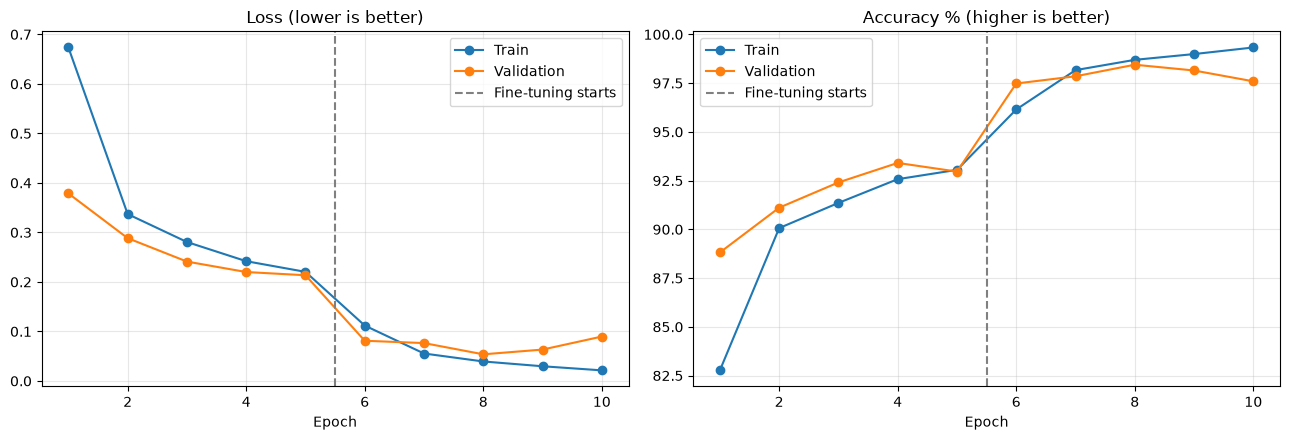

Best validation accuracy: 98.44%


In [15]:
epochs = range(1, len(history["train_loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(epochs, history["train_loss"], "o-", label="Train")
ax1.plot(epochs, history["val_loss"], "o-", label="Validation")
ax1.set_title("Loss (lower is better)"); ax1.set_xlabel("Epoch")
ax2.plot(epochs, [a * 100 for a in history["train_acc"]], "o-", label="Train")
ax2.plot(epochs, [a * 100 for a in history["val_acc"]], "o-", label="Validation")
ax2.set_title("Accuracy % (higher is better)"); ax2.set_xlabel("Epoch")
for ax in (ax1, ax2):
    ax.axvline(EPOCHS_FROZEN + 0.5, color="gray", linestyle="--", label="Fine-tuning starts")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(MODEL_DIR / "learning_curves.png", dpi=150)
plt.show()

print(f"Best validation accuracy: {max(history['val_acc']):.2%}")

## Step 12 – See the predictions

We load the **best** saved version of the model, then show 24 validation images (images it never trained on) with its guesses.

- **Green** title = correct, **red** = wrong
- The % is its **confidence**. `softmax` turns the 10 raw scores into probabilities that add up to 100%.

Look at the red ones: are they mistakes *you* might also make?

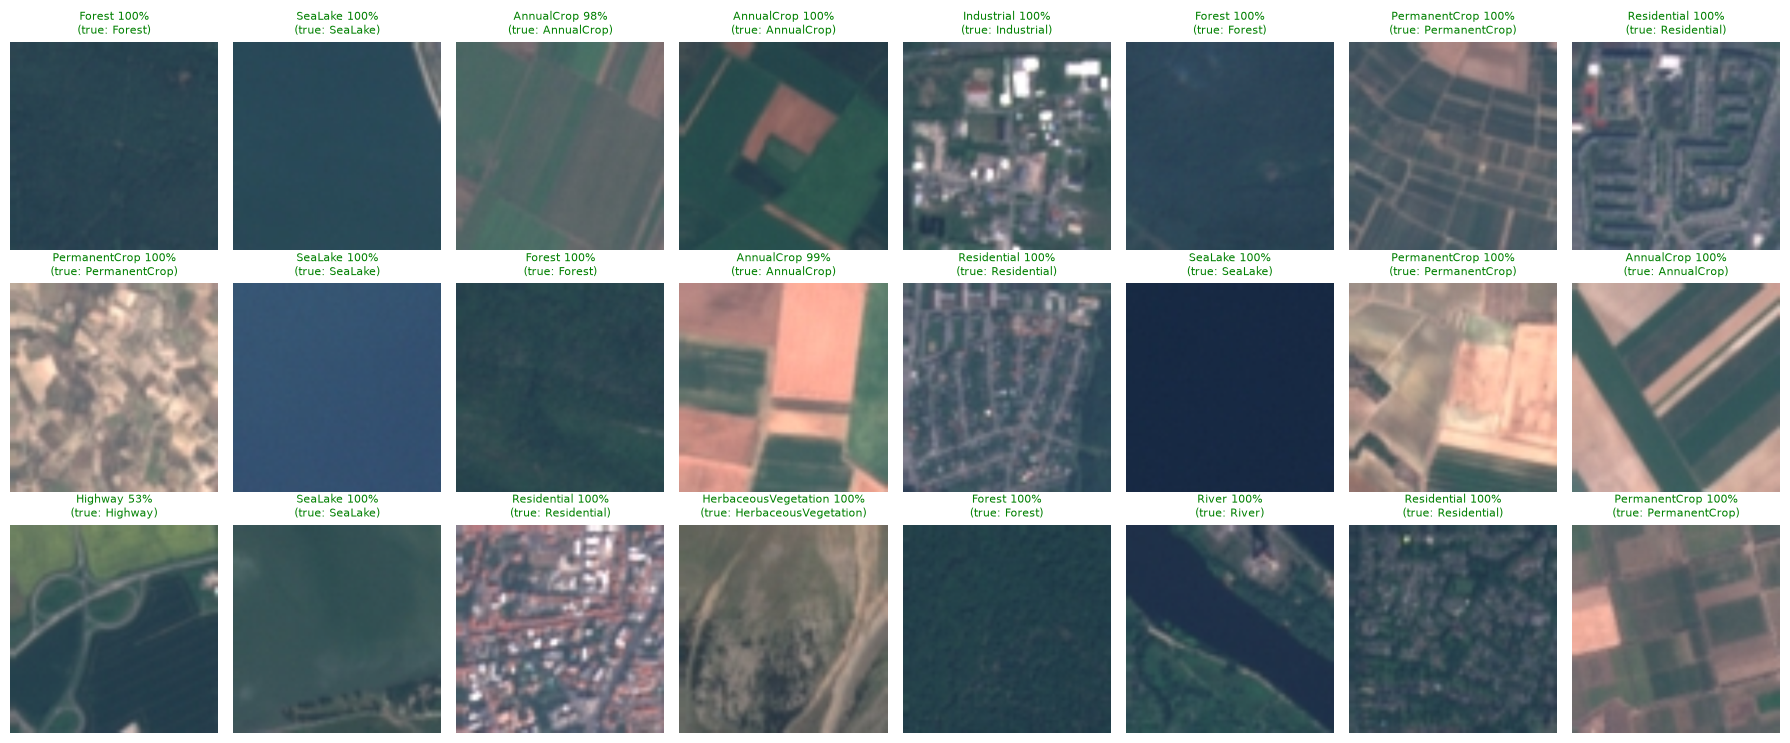

In [16]:
model.load_state_dict(torch.load(MODEL_PATH))
model.eval()

val_images, val_labels = next(iter(val_loader))
with torch.no_grad():
    probabilities = torch.softmax(model(val_images.to(device)), dim=1).cpu()
confidence, predicted = probabilities.max(1)

fig, axes = plt.subplots(3, 8, figsize=(18, 7.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(to_picture(val_images[i]))
    right = predicted[i] == val_labels[i]
    ax.set_title(f"{class_names[predicted[i]]} {confidence[i]:.0%}\n(true: {class_names[val_labels[i]]})",
                 fontsize=8, color="green" if right else "red")
    ax.axis("off")
plt.tight_layout(); plt.show()

### Its mistakes

The grid above may be all green, so let's go hunting: run through the whole validation set and show the images it got **wrong**.

Wrong: 49 out of 2700 validation images


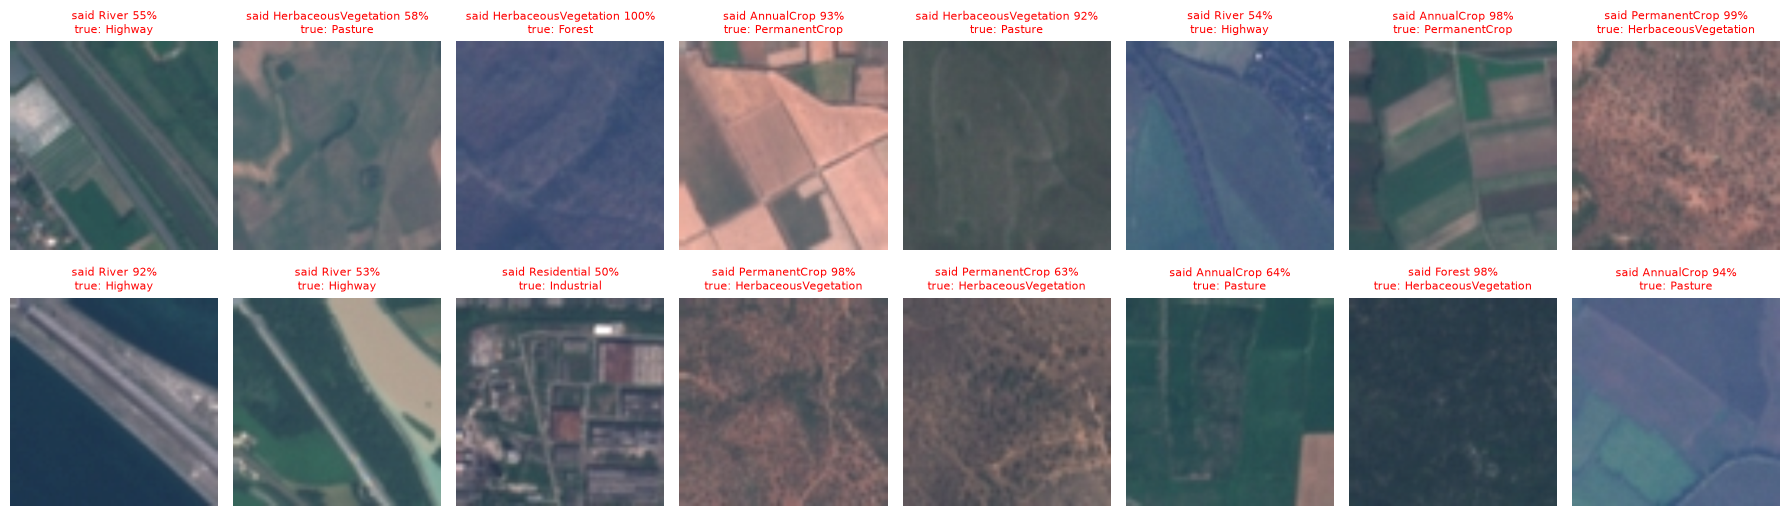

In [17]:
wrong = []
with torch.no_grad():
    for images, labels in val_loader:
        probs = torch.softmax(model(images.to(device)), dim=1).cpu()
        conf, preds = probs.max(1)
        for img, label, pred, c in zip(images, labels, preds, conf):
            if pred != label:
                wrong.append((img, label, pred, c))

print(f"Wrong: {len(wrong)} out of {len(val_set)} validation images")

shown = wrong[:16]
if shown:
    fig, axes = plt.subplots(2, 8, figsize=(18, 5.5), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (img, label, pred, c) in zip(axes.flat, shown):
        ax.imshow(to_picture(img))
        ax.set_title(f"said {class_names[pred]} {c:.0%}\ntrue: {class_names[label]}", fontsize=8, color="red")
    plt.tight_layout(); plt.show()

## Done!

Your trained model is saved at `models/resnet50_eurosat.pth` (git ignores `.pth` files, so it won't go to GitHub; it's ~95 MB). The learning curves are at `models/learning_curves.png`.

**Next notebook (03):** the final exam. Test-set accuracy, per-class scores, and a confusion matrix showing exactly which classes get mixed up.

## Think about it (answer in chat)

1. In Step 7 the untrained model got about 10% right. Why exactly 10%-ish and not 0% or 50%?
2. Look at the wrong predictions. Which classes get confused with each other? Does it match what you guessed in notebook 01?
3. Did fine-tuning (stage 2) help? Where on the learning curve do you see it?
4. When the model is wrong, is it usually *confident* (high %) or *unsure* (low %)? Why might that matter when we use it to detect deforestation?